In [195]:
import unicodedata

In [196]:
import pandas as pd


In [197]:
heart = pd.read_csv("processed.cleveland.data", header=None)

In [198]:
type(heart)

pandas.DataFrame

In [199]:
heart

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0,1
299,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,2
300,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,3
301,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,2.0,1.0,3.0,1


In [200]:
heart[0]

0      63.0
1      67.0
2      67.0
3      37.0
4      41.0
       ... 
298    45.0
299    68.0
300    57.0
301    57.0
302    38.0
Name: 0, Length: 303, dtype: float64

In [201]:
Columnas_a_usar = [0, 3, 4, 7, 9, 11, 13]

In [202]:
heart_df = heart[Columnas_a_usar]

In [203]:
heart_df

,0,3,4,7,9,11,13
0,63.0,145.0,233.0,150.0,2.3,0.0,0
1,67.0,160.0,286.0,108.0,1.5,3.0,2
2,67.0,120.0,229.0,129.0,2.6,2.0,1
3,37.0,130.0,250.0,187.0,3.5,0.0,0
4,41.0,130.0,204.0,172.0,1.4,0.0,0
...,...,...,...,...,...,...,...
298,45.0,110.0,264.0,132.0,1.2,0.0,1
299,68.0,144.0,193.0,141.0,3.4,2.0,2
300,57.0,130.0,131.0,115.0,1.2,1.0,3
301,57.0,130.0,236.0,174.0,0.0,1.0,1


In [204]:
heart_df.columns = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca", "diagnostic"]

In [205]:
heart_df

,age,trestbps,chol,thalach,oldpeak,ca,diagnostic
0,63.0,145.0,233.0,150.0,2.3,0.0,0
1,67.0,160.0,286.0,108.0,1.5,3.0,2
2,67.0,120.0,229.0,129.0,2.6,2.0,1
3,37.0,130.0,250.0,187.0,3.5,0.0,0
4,41.0,130.0,204.0,172.0,1.4,0.0,0
...,...,...,...,...,...,...,...
298,45.0,110.0,264.0,132.0,1.2,0.0,1
299,68.0,144.0,193.0,141.0,3.4,2.0,2
300,57.0,130.0,131.0,115.0,1.2,1.0,3
301,57.0,130.0,236.0,174.0,0.0,1.0,1


<Axes: xlabel='trestbps', ylabel='chol'>

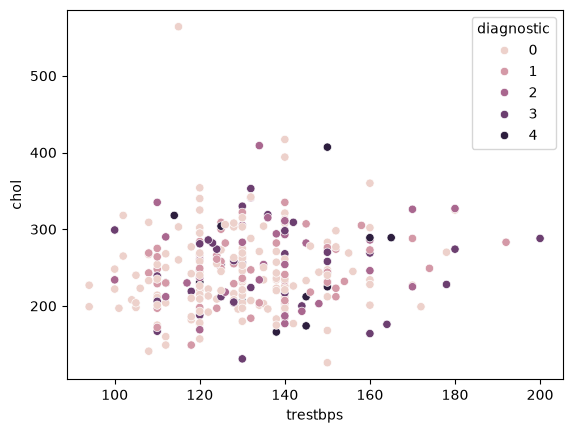

In [206]:
import seaborn as sns

sns.scatterplot(data=heart_df, x='trestbps', y='chol', hue="diagnostic")

In [207]:
heart_df.dtypes

age           float64
trestbps      float64
chol          float64
thalach       float64
oldpeak       float64
ca                str
diagnostic      int64
dtype: object

In [208]:
import numpy as np

In [209]:
heart_df['ca'] = heart_df['ca'].replace('?', np.nan)

In [210]:
heart_df

,age,trestbps,chol,thalach,oldpeak,ca,diagnostic
0,63.0,145.0,233.0,150.0,2.3,0.0,0
1,67.0,160.0,286.0,108.0,1.5,3.0,2
2,67.0,120.0,229.0,129.0,2.6,2.0,1
3,37.0,130.0,250.0,187.0,3.5,0.0,0
4,41.0,130.0,204.0,172.0,1.4,0.0,0
...,...,...,...,...,...,...,...
298,45.0,110.0,264.0,132.0,1.2,0.0,1
299,68.0,144.0,193.0,141.0,3.4,2.0,2
300,57.0,130.0,131.0,115.0,1.2,1.0,3
301,57.0,130.0,236.0,174.0,0.0,1.0,1


In [211]:
#Primera opción, elimimnar NaN
#heart_df.dropna()
#segunda opción, ponerle 0 a esos valores
#heart_df.fillna('0.0')
#tercer
    #heart_df['ca'].describe() y luego .valcounts
#heart_df['ca'].value_counts() #una forma es agarrar ese valor porque es la moda (o sea hacerlo cero), la otra opción es usar los valores cercanos, ahora para verlos usaremos...
#heart_df.ffill() #y así como hay ffill hay valguardfill
#heart_df.bfill() #Como abajo no hay nada pone NaN
heart_df = heart_df.dropna()
heart_df['ca'] = heart_df['ca'].astype(float).astype(int)

In [212]:
heart_df

,age,trestbps,chol,thalach,oldpeak,ca,diagnostic
0,63.0,145.0,233.0,150.0,2.3,0,0
1,67.0,160.0,286.0,108.0,1.5,3,2
2,67.0,120.0,229.0,129.0,2.6,2,1
3,37.0,130.0,250.0,187.0,3.5,0,0
4,41.0,130.0,204.0,172.0,1.4,0,0
...,...,...,...,...,...,...,...
297,57.0,140.0,241.0,123.0,0.2,0,1
298,45.0,110.0,264.0,132.0,1.2,0,1
299,68.0,144.0,193.0,141.0,3.4,2,2
300,57.0,130.0,131.0,115.0,1.2,1,3


In [213]:
heart_dfPrueba2 = heart_df.copy(deep=True)

In [214]:
heart_df['diagnostic']

0      0
1      2
2      1
3      0
4      0
      ..
297    1
298    1
299    2
300    3
301    1
Name: diagnostic, Length: 299, dtype: int64

In [215]:
heart_dfPrueba2['diagnostic']

0      0
1      2
2      1
3      0
4      0
      ..
297    1
298    1
299    2
300    3
301    1
Name: diagnostic, Length: 299, dtype: int64

In [216]:
from sklearn.model_selection import train_test_split

In [217]:
X_train, X_test, y_train, y_test = train_test_split(
                                                    heart_df[["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]],
                                                    heart_df[["diagnostic"]],
                                                    test_size=0.30,
                                                    random_state=0
)

In [218]:
X_train

,age,trestbps,chol,thalach,oldpeak,ca
283,35.0,122.0,192.0,174.0,0.0,0
44,61.0,130.0,330.0,169.0,0.0,0
243,61.0,134.0,234.0,145.0,2.6,2
190,50.0,129.0,196.0,163.0,0.0,0
152,67.0,115.0,564.0,160.0,1.6,0
...,...,...,...,...,...,...
253,51.0,120.0,295.0,157.0,0.6,0
194,68.0,120.0,211.0,115.0,1.5,0
117,35.0,138.0,183.0,182.0,1.4,0
47,50.0,150.0,243.0,128.0,2.6,0


In [219]:
type(X_train)

pandas.DataFrame

In [220]:
len(X_test)

90

In [221]:
from sklearn import preprocessing

In [222]:
X_train_norm = preprocessing.normalize(X_train)
X_test_norm = preprocessing. normalize(X_test)

In [223]:
#heart_df["ca"]=(heart_df["ca"] == "?" ).astype(int)

In [224]:
#heart_df["ca"]

In [225]:
type(X_train_norm)

numpy.ndarray

In [226]:
from sklearn.cluster import KMeans

In [227]:
kmeans = KMeans(n_clusters=4, random_state=0, n_init='auto')
kmeans.fit(X_train_norm)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](4, 6)","[[

In [228]:
from sklearn.metrics import silhouette_score

In [229]:
silhouette_score(X_train_norm, kmeans.labels_, metric='euclidean')

0.2904832126708751

In [230]:
#model = KMeans()

In [231]:
#heart_df.replace() una opción es usar el df y mo

In [232]:
#ax = sns.scatterplot(data= X_train, x = 'age', y ='ca', hue=3)

Hacer K neares neighbors de dos formas.

1. Usar dataset así como está
2. Transformar columna num para que ahora sea enfermo/sano

Sug: usar np.where para la transformación



In [233]:
from sklearn.neighbors import KNeighborsClassifier

In [234]:
np.where(heart_df["diagnostic"]==0, 0, 1) #si escribo heart_df["diagnostic"]=np.where(heart_df["diagnostic"]==0, 0, 1)  la columna se modifica a valores 0 y 1

array([0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0,
       1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1,
       1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1,
       1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0,
       1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1,
       0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1,
       1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0,
       0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1])

In [235]:
heart_df

,age,trestbps,chol,thalach,oldpeak,ca,diagnostic
0,63.0,145.0,233.0,150.0,2.3,0,0
1,67.0,160.0,286.0,108.0,1.5,3,2
2,67.0,120.0,229.0,129.0,2.6,2,1
3,37.0,130.0,250.0,187.0,3.5,0,0
4,41.0,130.0,204.0,172.0,1.4,0,0
...,...,...,...,...,...,...,...
297,57.0,140.0,241.0,123.0,0.2,0,1
298,45.0,110.0,264.0,132.0,1.2,0,1
299,68.0,144.0,193.0,141.0,3.4,2,2
300,57.0,130.0,131.0,115.0,1.2,1,3


In [236]:
#heart_dfPrueba2["diagnostic"]=np.where(heart_dfPrueba2["diagnostic"]==0, 0, 1)

In [237]:
#heart_dfPrueba2 #En efecto, se aplicó

In [238]:
heart_df['diagnostic']

0      0
1      2
2      1
3      0
4      0
      ..
297    1
298    1
299    2
300    3
301    1
Name: diagnostic, Length: 299, dtype: int64

In [239]:
Prueba = np.arange(5)
Prueba

array([0, 1, 2, 3, 4])

In [240]:
type(Prueba)
type(X_train_norm)

numpy.ndarray

In [241]:
#np.where( heart_df('diagnostic') = 0, )

In [242]:
heart_df


,age,trestbps,chol,thalach,oldpeak,ca,diagnostic
0,63.0,145.0,233.0,150.0,2.3,0,0
1,67.0,160.0,286.0,108.0,1.5,3,2
2,67.0,120.0,229.0,129.0,2.6,2,1
3,37.0,130.0,250.0,187.0,3.5,0,0
4,41.0,130.0,204.0,172.0,1.4,0,0
...,...,...,...,...,...,...,...
297,57.0,140.0,241.0,123.0,0.2,0,1
298,45.0,110.0,264.0,132.0,1.2,0,1
299,68.0,144.0,193.0,141.0,3.4,2,2
300,57.0,130.0,131.0,115.0,1.2,1,3


In [243]:
heart_dfPrueba = heart_df

In [244]:
heart_dfPrueba

,age,trestbps,chol,thalach,oldpeak,ca,diagnostic
0,63.0,145.0,233.0,150.0,2.3,0,0
1,67.0,160.0,286.0,108.0,1.5,3,2
2,67.0,120.0,229.0,129.0,2.6,2,1
3,37.0,130.0,250.0,187.0,3.5,0,0
4,41.0,130.0,204.0,172.0,1.4,0,0
...,...,...,...,...,...,...,...
297,57.0,140.0,241.0,123.0,0.2,0,1
298,45.0,110.0,264.0,132.0,1.2,0,1
299,68.0,144.0,193.0,141.0,3.4,2,2
300,57.0,130.0,131.0,115.0,1.2,1,3


In [245]:
def f(x):
    if x != 0:
        x = 1
    return x

In [246]:
f(2)

1

In [247]:
heart_dfPrueba['diagnostic'].value_counts()

diagnostic
0    161
1     54
2     36
3     35
4     13
Name: count, dtype: int64

In [248]:
heart_dfPrueba['diagnostic'] = heart_dfPrueba['diagnostic'].apply(f)

In [249]:
heart_dfPrueba

,age,trestbps,chol,thalach,oldpeak,ca,diagnostic
0,63.0,145.0,233.0,150.0,2.3,0,0
1,67.0,160.0,286.0,108.0,1.5,3,1
2,67.0,120.0,229.0,129.0,2.6,2,1
3,37.0,130.0,250.0,187.0,3.5,0,0
4,41.0,130.0,204.0,172.0,1.4,0,0
...,...,...,...,...,...,...,...
297,57.0,140.0,241.0,123.0,0.2,0,1
298,45.0,110.0,264.0,132.0,1.2,0,1
299,68.0,144.0,193.0,141.0,3.4,2,1
300,57.0,130.0,131.0,115.0,1.2,1,1


In [250]:
#Con esto diagnostic (num) se divide en dos, enfermo y sano

In [251]:
X_heart = heart_dfPrueba.iloc[:,:-1] 

In [252]:
y_heart = heart_dfPrueba['diagnostic']

In [253]:
y_heart

0      0
1      1
2      1
3      0
4      0
      ..
297    1
298    1
299    1
300    1
301    1
Name: diagnostic, Length: 299, dtype: int64

In [254]:
X_train_KN, X_test_KN, y_train_KN, y_test_KN = train_test_split(X_heart, y_heart, random_state=0) 

In [255]:
X_train_KN.shape

(224, 6)

In [256]:
knn = KNeighborsClassifier(n_neighbors=2)

In [257]:
knn.fit(X_train_KN, y_train_KN)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",2
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [258]:
print(f'Model accuracy {knn.score(X_test_KN, y_test_KN)}')

Model accuracy 0.52


In [259]:
y_pred = knn.predict(X_test_KN)

In [260]:
y_pred

array([1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 0])

In [261]:
from sklearn.model_selection import cross_val_score

In [262]:
k_values = list(range(1,21))

In [263]:
acc_scores = []
for k in k_values:
    KNN = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(KNN, X_heart, y_heart, scoring='accuracy', cv=5)
    acc_scores.append(np.mean(scores))

In [264]:
acc_scores

[np.float64(0.5785875706214689),
 np.float64(0.5617514124293785),
 np.float64(0.6254802259887006),
 np.float64(0.6254237288135593),
 np.float64(0.6455367231638418),
 np.float64(0.6254237288135593),
 np.float64(0.6354237288135594),
 np.float64(0.6154237288135593),
 np.float64(0.6253107344632769),
 np.float64(0.6453107344632768),
 np.float64(0.6487570621468927),
 np.float64(0.642090395480226),
 np.float64(0.6488135593220339),
 np.float64(0.6454802259887006),
 np.float64(0.6387570621468927),
 np.float64(0.648587570621469),
 np.float64(0.6485875706214689),
 np.float64(0.6487570621468927),
 np.float64(0.6387005649717514),
 np.float64(0.6488700564971752)]

In [265]:
np.argmax(acc_scores)

np.int64(19)

In [266]:
best_k_index = np.argmax(acc_scores)

In [ ]:
k_values[best_k_index]

20

In [294]:
acc_scores[best_k_index]

np.float64(0.5385310734463277)

In [ ]:
scores

array([0.65      , 0.6       , 0.61666667, 0.71666667, 0.66101695])

In [268]:
k_values[np.argmax(acc_scores)]

20

In [269]:
import matplotlib.pyplot as plt

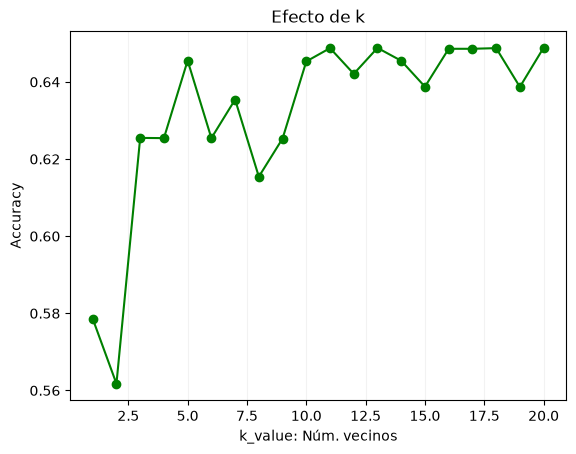

In [270]:
plt.plot(k_values, acc_scores, marker='o', color='green')
plt.xlabel('k_value: Núm. vecinos')
plt.ylabel('Accuracy')
plt.title('Efecto de k')
plt.grid(axis='x', color='.95')
plt.show()

In [271]:
k_values[np.int64(12)]

13

In [272]:
np.argmax(acc_scores)

np.int64(19)

In [273]:
acc_scores[np.argmax(acc_scores)]

np.float64(0.6488700564971752)

In [298]:
knn_20 = KNeighborsClassifier(n_neighbors=20)

In [299]:
knn_20.fit(X_train_KN, y_train_KN)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",20
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [300]:
knn_20.score(X_test_KN, y_test_KN)

0.64

In [277]:
heart_dfPrueba2

,age,trestbps,chol,thalach,oldpeak,ca,diagnostic
0,63.0,145.0,233.0,150.0,2.3,0,0
1,67.0,160.0,286.0,108.0,1.5,3,2
2,67.0,120.0,229.0,129.0,2.6,2,1
3,37.0,130.0,250.0,187.0,3.5,0,0
4,41.0,130.0,204.0,172.0,1.4,0,0
...,...,...,...,...,...,...,...
297,57.0,140.0,241.0,123.0,0.2,0,1
298,45.0,110.0,264.0,132.0,1.2,0,1
299,68.0,144.0,193.0,141.0,3.4,2,2
300,57.0,130.0,131.0,115.0,1.2,1,3


In [278]:
heart_dfPrueba2["diagnostic"]

0      0
1      2
2      1
3      0
4      0
      ..
297    1
298    1
299    2
300    3
301    1
Name: diagnostic, Length: 299, dtype: int64

In [279]:
X_heart_P2 = heart_dfPrueba2.iloc[:,:-1] 

In [280]:
y_heart_P2 = heart_dfPrueba2['diagnostic']

In [281]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(X_heart_P2, y_heart_P2, random_state=0)

In [282]:
acc_scores = []
for k in k_values:
    KNN = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(KNN, X_heart_P2, y_heart_P2, scoring='accuracy', cv=5)
    acc_scores.append(np.mean(scores))

In [283]:
scores

array([0.56666667, 0.53333333, 0.51666667, 0.51666667, 0.55932203])

In [284]:
acc_scores

[np.float64(0.41785310734463277),
 np.float64(0.4815819209039548),
 np.float64(0.49135593220338974),
 np.float64(0.4849152542372881),
 np.float64(0.4948587570621469),
 np.float64(0.5250847457627119),
 np.float64(0.5218079096045197),
 np.float64(0.5117514124293785),
 np.float64(0.5218079096045198),
 np.float64(0.5217514124293785),
 np.float64(0.5350847457627118),
 np.float64(0.5316949152542374),
 np.float64(0.5284180790960453),
 np.float64(0.5384180790960452),
 np.float64(0.535141242937853),
 np.float64(0.5451412429378532),
 np.float64(0.535141242937853),
 np.float64(0.5318079096045197),
 np.float64(0.541864406779661),
 np.float64(0.5385310734463277)]

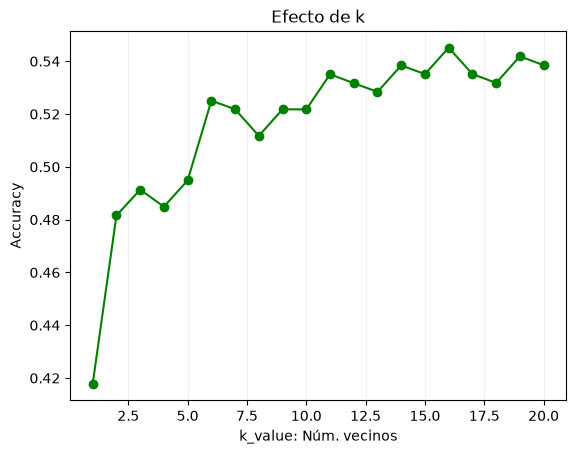

In [285]:
plt.plot(k_values, acc_scores, marker='o', color='green')
plt.xlabel('k_value: Núm. vecinos')
plt.ylabel('Accuracy')
plt.title('Efecto de k')
plt.grid(axis='x', color='.95')
plt.show()

In [286]:
acc_scores[np.argmax(acc_scores)]

np.float64(0.5451412429378532)

In [287]:
np.argmax(acc_scores)

np.int64(15)

In [288]:
k_values[np.argmax(acc_scores)]

16

In [289]:
knn_13 = KNeighborsClassifier(n_neighbors=13)

In [290]:
knn_13.fit(X_train2, y_train2)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",13
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](5,)","[0,1,2,3,4]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [291]:
knn_13.score(X_test2, y_test2)

0.52